In [2]:
import anndata as ad
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os, sys, re

In [3]:
metadata = pd.read_csv('/work/magroup/skrieger/Syndri/data/datasets/brain_merfish/raw/spatial/Zhuang-ABCA-4_cell_metadata_with_cluster_annotation.csv')
metadata = metadata.set_index('cell_label').drop(columns=['brain_section_label'])

In [4]:
metadata

,feature_matrix_label,donor_label,donor_genotype,donor_sex,cluster_alias,x,y,z,subclass_confidence_score,cluster_confidence_score,...,neurotransmitter,class,subclass,supertype,cluster,neurotransmitter_color,class_color,subclass_color,supertype_color,cluster_color
cell_label,,,,,,,,,,,,,,,,,,,,,
177536119734259275144748435471942472531,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,5249,12.845605,3.428535,1.958952,0.998365,0.806205,...,NaN,33 Vascular,332 SMC NN,1192 SMC NN_1,5307 SMC NN_1,#666666,#858881,#FF9F73,#1F6566,#009945
256532006537596385088807329967308781746,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,4167,12.854068,3.466185,1.958952,0.928926,0.928926,...,GABA,28 CB GABA,311 CBX MLI Megf11 Gaba,1149 CBX MLI Megf11 Gaba_1,5188 CBX MLI Megf11 Gaba_1,#FF3358,#FFFB46,#8BCC5C,#246600,#4F2E66
28801318882950773770397006451868070066,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,5252,12.828245,3.409277,1.958952,0.963517,0.948538,...,NaN,33 Vascular,333 Endo NN,1193 Endo NN_1,5309 Endo NN_1,#666666,#858881,#994567,#00992A,#5C9994
301971869963235435117242882149875853185,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,5252,12.827268,3.403092,1.958952,0.999984,0.853408,...,NaN,33 Vascular,333 Endo NN,1193 Endo NN_1,5309 Endo NN_1,#666666,#858881,#994567,#00992A,#5C9994
81203938259029510162263594992098070595,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,5249,12.828462,3.410416,1.958952,0.999948,0.999948,...,NaN,33 Vascular,332 SMC NN,1192 SMC NN_1,5307 SMC NN_1,#666666,#858881,#FF9F73,#1F6566,#009945
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
207078638049612663505414491993744973724,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,5283,3.631468,4.047762,1.780537,0.999987,0.999987,...,NaN,34 Immune,334 Microglia NN,1194 Microglia NN_1,5312 Microglia NN_1,#666666,#825f45,#CC1F4E,#62CC3D,#651FCC
269688622729976403473132483008812650057,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,5283,3.626968,3.951028,1.780537,0.805506,0.805506,...,NaN,34 Immune,334 Microglia NN,1194 Microglia NN_1,5312 Microglia NN_1,#666666,#825f45,#CC1F4E,#62CC3D,#651FCC
32317399564312907213846667957826182632,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,5254,3.642379,3.875565,1.780537,0.997058,0.825222,...,NaN,33 Vascular,333 Endo NN,1193 Endo NN_1,5310 Endo NN_1,#666666,#858881,#994567,#00992A,#FFB473


In [58]:
adata = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/brain_merfish/raw/spatial/Zhuang-ABCA-4-raw.h5ad')
adata

AnnData object with n_obs × n_vars = 215278 × 1122
    obs: 'brain_section_label'
    var: 'gene_symbol'

In [59]:
adata.obs = adata.obs.merge(metadata,left_index=True,right_index=True,how='left')

In [60]:
adata.obs.dropna()

,brain_section_label,feature_matrix_label,donor_label,donor_genotype,donor_sex,cluster_alias,x,y,z,subclass_confidence_score,...,neurotransmitter,class,subclass,supertype,cluster,neurotransmitter_color,class_color,subclass_color,supertype_color,cluster_color
cell_label,,,,,,,,,,,,,,,,,,,,,
268505080119143956153850457583020766266,Zhuang-ABCA-4.002,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,195.0,9.875388,2.492802,1.958952,0.977098,...,Glut,01 IT-ET Glut,006 L4/5 IT CTX Glut,0027 L4/5 IT CTX Glut_5,0098 L4/5 IT CTX Glut_5,#2B93DF,#FA0087,#3DCCB7,#639917,#661B0F
163738688919619248469500573847520748166,Zhuang-ABCA-4.002,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,197.0,9.836545,2.292856,1.958952,0.984557,...,Glut,01 IT-ET Glut,006 L4/5 IT CTX Glut,0026 L4/5 IT CTX Glut_4,0092 L4/5 IT CTX Glut_4,#2B93DF,#FA0087,#3DCCB7,#0F6619,#543D66
176544682826876004247479461613419405173,Zhuang-ABCA-4.002,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,198.0,9.830632,2.395660,1.958952,0.999987,...,Glut,01 IT-ET Glut,006 L4/5 IT CTX Glut,0023 L4/5 IT CTX Glut_1,0074 L4/5 IT CTX Glut_1,#2B93DF,#FA0087,#3DCCB7,#3B9900,#581F66
255232178141179451023198025486487605162,Zhuang-ABCA-4.002,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,198.0,9.821680,2.448716,1.958952,0.887946,...,Glut,01 IT-ET Glut,006 L4/5 IT CTX Glut,0023 L4/5 IT CTX Glut_1,0074 L4/5 IT CTX Glut_1,#2B93DF,#FA0087,#3DCCB7,#3B9900,#581F66
88900940333761837154920686720409479104,Zhuang-ABCA-4.002,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,198.0,9.842784,2.438572,1.958952,0.999266,...,Glut,01 IT-ET Glut,006 L4/5 IT CTX Glut,0023 L4/5 IT CTX Glut_1,0074 L4/5 IT CTX Glut_1,#2B93DF,#FA0087,#3DCCB7,#3B9900,#581F66
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67574644470618519179319317484458435510,Zhuang-ABCA-4.003,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,1405.0,7.924314,2.921916,2.914369,0.999945,...,Glut,04 DG-IMN Glut,037 DG Glut,0137 DG Glut_2,0507 DG Glut_2,#2B93DF,#16f2f2,#CC2400,#F573FF,#99176A
86924414659528614697505758811861073480,Zhuang-ABCA-4.003,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,1403.0,7.932762,2.923660,2.914369,0.999940,...,Glut,04 DG-IMN Glut,037 DG Glut,0137 DG Glut_2,0505 DG Glut_2,#2B93DF,#16f2f2,#CC2400,#F573FF,#CC603D
93687685914378483949420823405358061175,Zhuang-ABCA-4.003,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,1403.0,7.752531,2.857279,2.914369,0.999963,...,Glut,04 DG-IMN Glut,037 DG Glut,0137 DG Glut_2,0505 DG Glut_2,#2B93DF,#16f2f2,#CC2400,#F573FF,#CC603D


In [ ]:
#merge(metadata,left_index=True, right_on='cell_label',how='left')


Index(['229250388033532008701576616905162636267',
       '169110121737161451906806777651198051339',
       '208150625918481063555455826151529682383',
       '250204177404098111228765620724641433980',
       '176147556591204031520681811910768151276',
       '287887851189318425070985856829950713999',
       '336069588715653396287763327635800417949',
       '26293604527117673151169255665674662896',
       '330510439485241295234642174306231815639',
       '53884165802957456435676247629890272405',
       ...
       '267796916367621747766286773117270685957',
       '61822534463540761959701154027601668848',
       '123903996151246789706208141490747644896',
       '75406197005604595187011850739186450308',
       '244494576366025873924233249492682574323',
       '39204761539991190934768317386666031343',
       '119189021761575603875505232930484615474',
       '246448259732239213625988147134969774664',
       '338749761398066122277535696849597763313',
       '208310273664740998320466646194827109

In [64]:
import scanpy as sc
from sklearn.decomposition import PCA
from umap import UMAP
import numpy as np
from geosketch import gs

X = adata.X.copy()
X = np.log1p(X)
X = (X-np.mean(X,axis=0))/(np.std(X,axis=0)+np.finfo(float).eps)

X_pca = PCA(n_components=30).fit_transform(X)

X_umap = UMAP(n_components=2).fit_transform(X_pca)

adata.obsm['X_umap_spatialonly'] = X_umap

Text(0.5, 1.0, 'ABCA-4')

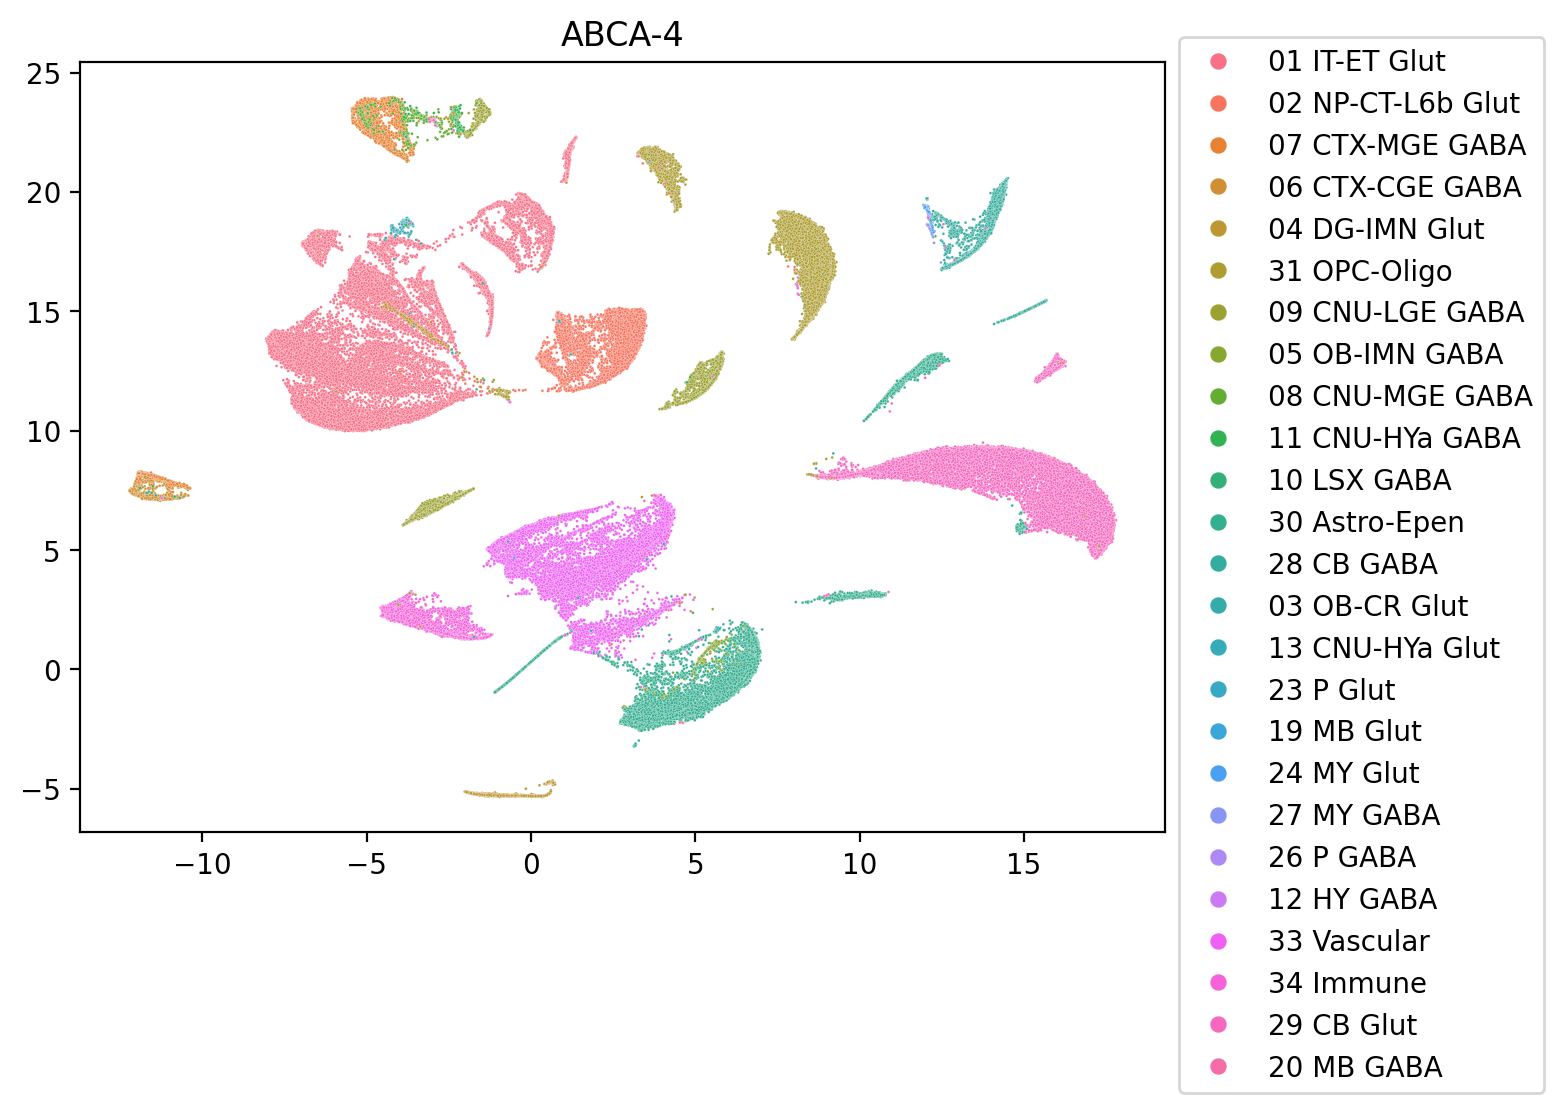

In [66]:
fig,ax = plt.subplots(figsize=(7,5),dpi=200)
ax = sns.scatterplot(x=adata.obsm['X_umap_spatialonly'][:,0],y=adata.obsm['X_umap_spatialonly'][:,1],hue=adata.obs['class'],s=1,ax=ax)
ax.legend(bbox_to_anchor=(1,1.05),markerscale=6)
ax.set_title('ABCA-4')

In [ ]:
ax = sns.scatterplot(x=adata.obs['x'],y=adata.obs['y'],hue=adata.obs['class'],palette='tab20',s=1)
ax.legend(bbox_to_anchor=(1,1.05),markerscale=6)

In [ ]:
adata.obs['brain_section_label']